# Kennzahlen aus CVAT-annotierten Bildern

Dieses Notebook berechnet einfache Metriken auf Basis unserer selbst gelabelten CVAT-Masken (TrainId/Cityscapes-Schema):
- Pixelanteil pro Klasse (Pixelanzahl / Gesamtpixel)
- Instanzanzahl pro Klasse (Connected Components auf der Klassen-Maske)
- Klassen-Entropie als Maß für Szenen-Komplexität (nur nicht-ignorierte Klassen)


## Imports und Pfade
Wir lesen die CVAT-Labelmap (RGB -> Klassenname) und nutzen zusaetzlich `labels.py`, um `trainId`/`id` pro Klasse zu kennen. Die Pfade zeigen auf `05_evaluation/CVATAnnotations` (oder `05_evaluation/CVAT Annotations`, je nach Ordnername).

In [117]:
from pathlib import Path
import sys
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from PIL import Image
import cv2
import matplotlib.pyplot as plt

# Repo-Root finden: vom aktuellen cwd nach oben, suche nach Ordnernamen mit/ohne Leerzeichen
CWD = Path.cwd().resolve()
CANDIDATE_NAMES = [
    ("05_evaluation", "CVATAnnotations"),
    ("05_evaluation", "CVAT Annotations"),
]
REPO_ROOT = None
ANNOTATION_DIR = None
for cand in [CWD, *CWD.parents]:
    for p1, p2 in CANDIDATE_NAMES:
        candidate_dir = cand / p1 / p2
        if candidate_dir.exists():
            REPO_ROOT = cand
            ANNOTATION_DIR = candidate_dir
            break
    if REPO_ROOT is not None:
        break

if REPO_ROOT is None or ANNOTATION_DIR is None:
    raise AssertionError(
        f"Kann Repo-Root nicht finden. Bitte Notebook im Repo oder Unterordner starten. CWD={CWD}"
    )

LABELMAP_PATH = ANNOTATION_DIR / "labelmap.txt"

assert ANNOTATION_DIR.exists(), f"Ordner fehlt: {ANNOTATION_DIR}"
assert LABELMAP_PATH.exists(), f"labelmap.txt fehlt: {LABELMAP_PATH}"

# labels.py fur trainId/id Mapping laden
if str(REPO_ROOT) not in sys.path:
    sys.path.append(str(REPO_ROOT))
try:
    from labels import name2label
except ImportError as exc:
    raise ImportError("labels.py konnte nicht geladen werden. Bitte Notebook aus dem Repo-Root starten.") from exc


## Labelmap einlesen
Wir lesen `labelmap.txt` (RGB-Farbe u Klassenname) und ergänzen `trainId`/`id` aus `labels.py`. Die Reihenfolge der Klassen in der Labelmap bestimmt die Spalten-Reihenfolge in den Ergebnis-Tabellen.

In [118]:
def load_labelmap(labelmap_path: Path):
    '''Parst labelmap.txt aus CVAT und verbindet sie mit trainId/id aus labels.py.'''
    classes = []
    color_to_class = {}

    for line in labelmap_path.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        try:
            name, rest = line.split(":", 1)
            color_str = rest.split(":", 1)[0]
        except ValueError:
            continue

        rgb = tuple(int(c) for c in color_str.split(","))
        train_id = name2label[name].trainId if name in name2label else None
        rec = {
            "class_id": len(classes),
            "name": name,
            "color": rgb,
            "trainId": train_id,
            "id": name2label[name].id if name in name2label else None,
        }
        classes.append(rec)
        color_to_class[rgb] = rec

    return classes, color_to_class

classes, color_to_class = load_labelmap(LABELMAP_PATH)
class_names = [c["name"] for c in classes]

pd.DataFrame(classes)[["class_id", "name", "color", "trainId", "id"]]


,class_id,name,color,trainId,id
0,0,background,"(0, 0, 0)",NaN,NaN
1,1,bicycle,"(119, 11, 32)",17.0,33.0
2,2,building,"(70, 70, 70)",3.0,11.0
3,3,bus,"(0, 60, 100)",14.0,28.0
4,4,car,"(0, 0, 142)",12.0,26.0
5,5,guard rail,"(180, 165, 180)",4.0,14.0
6,6,motorcycle,"(0, 0, 230)",16.0,32.0
7,7,parking,"(250, 170, 160)",255.0,9.0
8,8,person,"(220, 20, 60)",10.0,24.0
9,9,pole,"(153, 153, 153)",5.0,17.0


## Hilfsfunktionen für Kennzahlen
- Pixelzählung pro Klasse via `np.unique` auf der Farbmaske (RGB).
- Instanzzählung pro Klasse via `cv2.connectedComponents` auf der Binärmaske der jeweiligen Klasse.
- Entropie auf Basis der relativen Pixelverteilung der **nicht ignorierten** Klassen (trainId u {255, -1} bzw. `background` werden ignoriert).

In [119]:
def compute_metrics(
    mask_path: Path,
    classes,
    color_to_class,
    ignore_train_ids={255, -1},
    ignore_names={"background"},
):
    mask = np.array(Image.open(mask_path))
    if mask.ndim != 3 or mask.shape[2] != 3:
        raise ValueError(f"Maske {mask_path} hat unerwartete Form: {mask.shape}")

    h, w, _ = mask.shape
    total_pixels = h * w
    name_to_rec = {c["name"]: c for c in classes}

    # Pixel pro Klasse (RGB u Name)
    class_counts = {c["name"]: 0 for c in classes}
    flat = mask.reshape(-1, 3)
    colors, counts = np.unique(flat, axis=0, return_counts=True)
    for color, count in zip(colors, counts):
        rec = color_to_class.get(tuple(color.tolist()))
        if rec is None:
            continue  # unbekannte Farbe wird ignoriert
        class_counts[rec["name"]] += int(count)

    # Instanzanzahl pro Klasse via Connected Components auf der jeweiligen Binurmaske
    class_instances = {c["name"]: 0 for c in classes}
    for rec in classes:
        color = np.array(rec["color"], dtype=np.uint8)
        binary = np.all(mask == color, axis=2).astype(np.uint8)
        num_components, _ = cv2.connectedComponents(binary)
        class_instances[rec["name"]] = max(num_components - 1, 0)  # minus Hintergrund-Label 0

    # Pixelanteile (immer bezogen auf alle Pixel des Bildes)
    class_shares = {
        name: (count / total_pixels if total_pixels else 0.0)
        for name, count in class_counts.items()
    }

    def is_ignored(name: str) -> bool:
        rec = name_to_rec[name]
        return (rec["trainId"] in ignore_train_ids) or (name in ignore_names)

    # Entropie nur uber gultige Klassen
    valid_pixel_sum = sum(count for name, count in class_counts.items() if not is_ignored(name))
    entropy = 0.0
    if valid_pixel_sum > 0:
        for name, count in class_counts.items():
            if is_ignored(name) or count == 0:
                continue
            p = count / valid_pixel_sum
            entropy -= p * math.log(p)

    present_classes = [name for name, count in class_counts.items() if count > 0 and not is_ignored(name)]

    return {
        "image": mask_path.name,
        "width": w,
        "height": h,
        "total_pixels": total_pixels,
        "class_counts": class_counts,
        "class_shares": class_shares,
        "instance_counts": class_instances,
        "entropy": entropy,
        "num_present_classes": len(present_classes),
        "present_classes": present_classes,
    }


## Auswertung über alle CVAT-Masken
Wir laufen über alle `*.png`-Masken in `05_evaluation/CVAT Annotations`, berechnen Kennzahlen und geben drei Tabellen aus:
- **summary_df**: Basis-Infos + Entropie + Liste der vorkommenden Klassen
- **shares_df**: Pixelanteile pro Klasse (pro Bild)
- **instances_df**: Instanzanzahlen pro Klasse (pro Bild)

In [120]:
png_files = sorted(ANNOTATION_DIR.glob("*.png"))
assert png_files, "Keine *.png Masken im Ordner gefunden."

rows = [compute_metrics(png, classes, color_to_class) for png in png_files]

summary_df = pd.DataFrame({
    "image": [r["image"] for r in rows],
    "height": [r["height"] for r in rows],
    "width": [r["width"] for r in rows],
    "entropy": [r["entropy"] for r in rows],
    "num_present_classes": [r["num_present_classes"] for r in rows],
    "present_classes": [", ".join(r["present_classes"]) for r in rows],
}).set_index("image")

counts_df = pd.DataFrame([r["class_counts"] for r in rows], index=[r["image"] for r in rows]).fillna(0).astype(int)
shares_df = pd.DataFrame([r["class_shares"] for r in rows], index=[r["image"] for r in rows]).fillna(0.0)
instances_df = pd.DataFrame([r["instance_counts"] for r in rows], index=[r["image"] for r in rows]).fillna(0).astype(int)

summary_df, shares_df, instances_df


(           height  width   entropy  num_present_classes  \
 image                                                     
 bild1.png    1536   2048  1.241006                   14   
 bild2.png    1382   2047  1.249154                   12   
 bild3.png    1536   2048  1.501315                   12   
 
                                              present_classes  
 image                                                         
 bild1.png  bicycle, building, bus, car, motorcycle, perso...  
 bild2.png  bicycle, building, bus, car, person, pole, rid...  
 bild3.png  bicycle, building, car, person, pole, rider, r...  ,
            background   bicycle  building       bus       car  guard rail  \
 bild1.png    0.015711  0.000102  0.076060  0.002391  0.082931         0.0   
 bild2.png    0.001547  0.000515  0.363691  0.000563  0.010987         0.0   
 bild3.png    0.027431  0.001144  0.198590  0.000000  0.005171         0.0   
 
            motorcycle  parking    person      pole  ...     ri

## Visualisierung der Kennzahlen
Wir plotten die wichtigsten Kennzahlen als Balkendiagramme:
- Durchschnittlicher Pixelanteil pro Klasse (Top 10)
- Gesamtanzahl Instanzen pro Klasse (Top 10)
- Pixelanteile pro Bild (gestapelt, Top-K Klassen)
- Instanzanzahl pro Bild (Top-K Klassen)

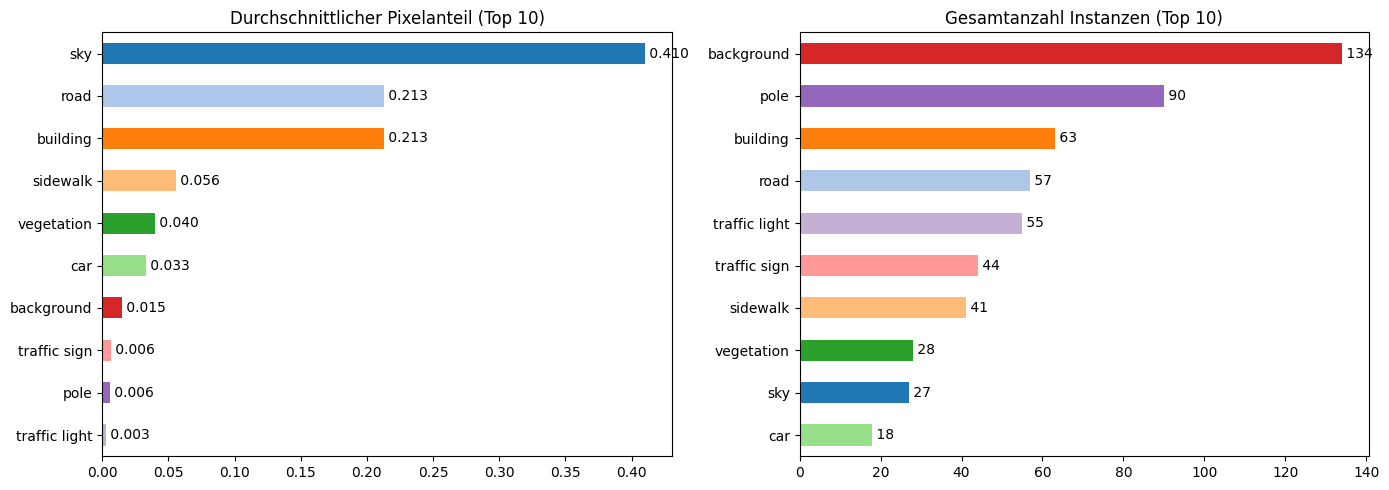

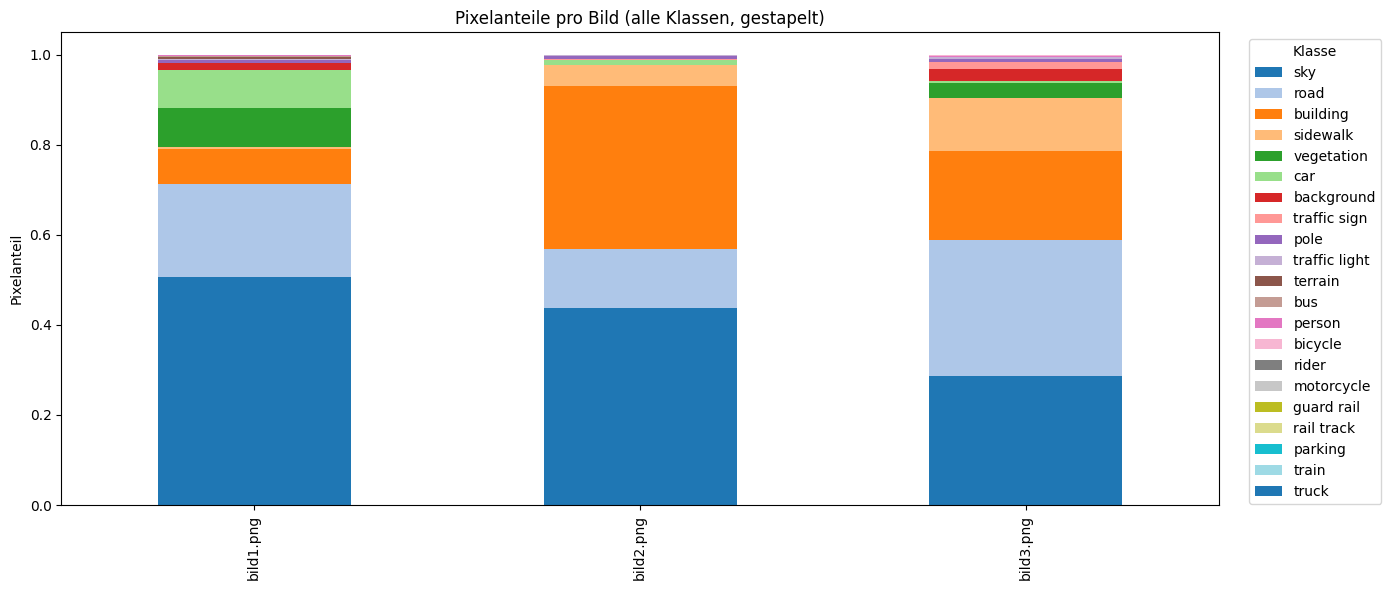

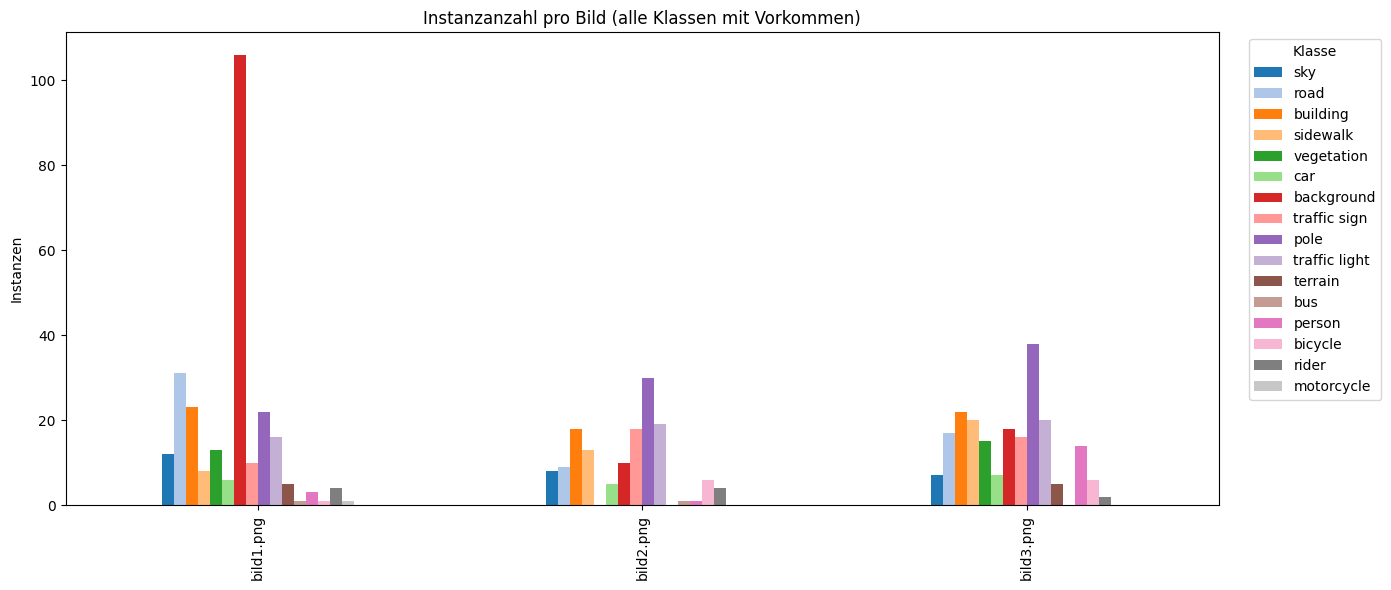

In [121]:
# Aggregierte Metriken
mean_shares = shares_df.mean().sort_values(ascending=False)
total_instances = instances_df.sum().sort_values(ascending=False)

# Einheitliche Farbpalette pro Klasse (wird auch fur Watershed genutzt)
classes_for_plots = mean_shares.index.tolist()
cmap = plt.get_cmap("tab20")
palette = {cls: cmap(i % cmap.N) for i, cls in enumerate(classes_for_plots)}


def nice_barh(series, title, default_color="steelblue"):
    colors = [palette.get(idx, default_color) for idx in series.index]
    ax = plt.gca()
    series.plot(kind="barh", color=colors, ax=ax)
    ax.invert_yaxis()
    ax.set_xlabel("")
    ax.set_title(title)
    for i, v in enumerate(series):
        ax.text(v, i, f" {v:.3f}" if v < 1 else f" {int(v)}", va="center")
    return ax

# Figure 1: Global Top 10 Shares & Instances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plt.sca(axes[0]); nice_barh(mean_shares.head(10), "Durchschnittlicher Pixelanteil (Top 10)")
plt.sca(axes[1]); nice_barh(total_instances.head(10), "Gesamtanzahl Instanzen (Top 10)", default_color="salmon")
plt.tight_layout()
plt.show()

# Pixelanteile pro Bild, alle Klassen (gestapelt)
fig, ax = plt.subplots(figsize=(14, 6))
shares_df[classes_for_plots].plot(kind="bar", stacked=True, ax=ax, color=[palette[c] for c in classes_for_plots])
ax.set_ylabel("Pixelanteil")
ax.set_title("Pixelanteile pro Bild (alle Klassen, gestapelt)")
ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Instanzanzahl pro Bild, alle Klassen mit Vorkommen
nonzero_classes = [c for c in classes_for_plots if instances_df[c].sum() > 0]
fig, ax = plt.subplots(figsize=(14, 6))
instances_df[nonzero_classes].plot(kind="bar", ax=ax, color=[palette[c] for c in nonzero_classes])
ax.set_ylabel("Instanzen")
ax.set_title("Instanzanzahl pro Bild (alle Klassen mit Vorkommen)")
ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Alternative Instanztrennung (Distance Transform + Watershed)

Kurze Notizen fuer mich, was hier passiert und was ich anpassen kann:
- Baseline ist Connected Components (CC). Watershed probiere ich nur fuer Objektklassen wie person/rider/bicycle/motorcycle/car/truck/bus/train/traffic light/traffic sign. Fuer andere Klassen bleibt CC.
- Ablauf: Binarmaske -> (optional) Erosion -> Distance Transform -> lokale Peaks als Seeds -> Connected Components auf Seeds -> Watershed -> Instanzen zaehlen.
- dist_rel: Schwellwert fuer Seeds (relativ zum Max der Distance Map). Kleiner = mehr Seeds = mehr Splits.
- min_area: Filter fuer sehr kleine Fragmente. Groesser = weniger Noise, aber evtl. weniger Splits.
- erode_iters: Trennt schmale Bruecken zwischen Objekten. Zu hoch kann Objekte kaputt machen.
- use_peaks: True nutzt lokale Maxima als Seeds (mehr Seeds, feinere Trennung). False nutzt nur Threshold.
- instance_classes: Menge der Klassen, fuer die Watershed aktiv ist.


In [122]:
def watershed_instance_counts(
    mask_path: Path,
    classes,
    color_to_class,
    dist_rel=0.15,
    min_area=4,
    erode_iters=2,
    use_peaks=True,
    instance_classes=None,
):
    # Watershed-basierte Instanztrennung fuer Objektklassen
    if instance_classes is None:
        instance_classes = {
            "person", "rider", "bicycle", "motorcycle", "car", "truck", "bus", "train",
            "traffic light", "traffic sign"
        }

    mask = np.array(Image.open(mask_path))
    if mask.ndim != 3 or mask.shape[2] != 3:
        raise ValueError(f"Maske {mask_path} hat unerwartete Form: {mask.shape}")

    counts = {c["name"]: 0 for c in classes}
    kernel = np.ones((3, 3), np.uint8)

    for rec in classes:
        name = rec["name"]
        color = np.array(rec["color"], dtype=np.uint8)
        binary = (np.all(mask == color, axis=2)).astype(np.uint8)
        if binary.sum() == 0:
            continue

        # Baseline: Connected Components
        cc_num, _ = cv2.connectedComponents(binary)
        cc_count = max(cc_num - 1, 0)

        # Nur Objektklassen mit Watershed splitten
        if name not in instance_classes:
            counts[name] = cc_count
            continue

        # Optional: schmale Bruecken trennen
        work = binary.copy()
        if erode_iters > 0:
            work = cv2.erode(work, kernel, iterations=erode_iters)
            if work.sum() == 0:
                work = binary

        dist = cv2.distanceTransform(work, cv2.DIST_L2, 5)
        max_d = dist.max()
        if max_d <= 0:
            counts[name] = cc_count
            continue

        dist_norm = dist / max_d

        if use_peaks:
            # Lokale Maxima als Seeds
            dilated = cv2.dilate(dist, kernel)
            peaks = (dist == dilated) & (dist_norm > dist_rel)
            seed_mask = peaks.astype(np.uint8)
        else:
            # Einfache Schwelle
            seed_mask = (dist_norm > dist_rel).astype(np.uint8)

        seed_mask = cv2.morphologyEx(seed_mask, cv2.MORPH_OPEN, kernel)
        num_markers, markers = cv2.connectedComponents(seed_mask)
        if num_markers <= 1:
            counts[name] = cc_count
            continue

        markers = markers + 1  # Hintergrund=1, Seeds ab 2
        markers[binary == 0] = 0

        img_for_ws = cv2.cvtColor((binary * 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
        markers = cv2.watershed(img_for_ws, markers)

        unique, areas = np.unique(markers, return_counts=True)
        ws_count = 0
        for lbl, area in zip(unique, areas):
            if lbl > 1 and area >= min_area:
                ws_count += 1

        counts[name] = ws_count

    counts["__image__"] = mask_path.name
    return counts

# Ausfuehren fuer alle PNGs
ws_rows = [watershed_instance_counts(png, classes, color_to_class) for png in png_files]
ws_instances_df = pd.DataFrame(ws_rows).set_index("__image__").fillna(0).astype(int)

ws_instances_df.head()


,background,bicycle,building,bus,car,guard rail,motorcycle,parking,person,pole,...,rider,road,sidewalk,sky,terrain,traffic light,traffic sign,train,truck,vegetation
__image__,,,,,,,,,,,,,,,,,,,,,
bild1.png,106,1,23,1,6,0,1,0,3,22,...,4,31,8,12,5,16,10,0,0,13
bild2.png,10,6,18,1,5,0,0,0,1,30,...,4,9,13,8,0,19,18,0,0,0
bild3.png,18,6,22,0,7,0,0,0,14,38,...,2,17,20,7,5,20,16,0,0,15


## Visualisierung der Watershed-Instanzzählung
Wir vergleichen die alternative Instanzzählung (Distance Transform + Watershed):
- Gesamtinstanzen pro Klasse (alle Klassen mit Vorkommen)
- Instanzen pro Bild (alle Klassen mit Vorkommen)


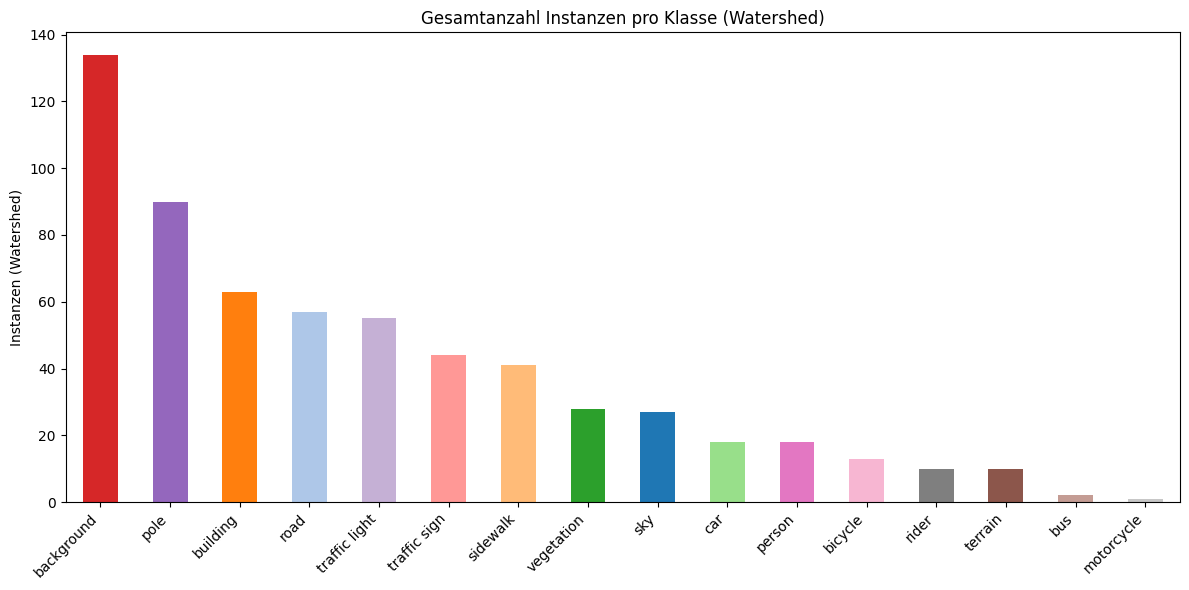

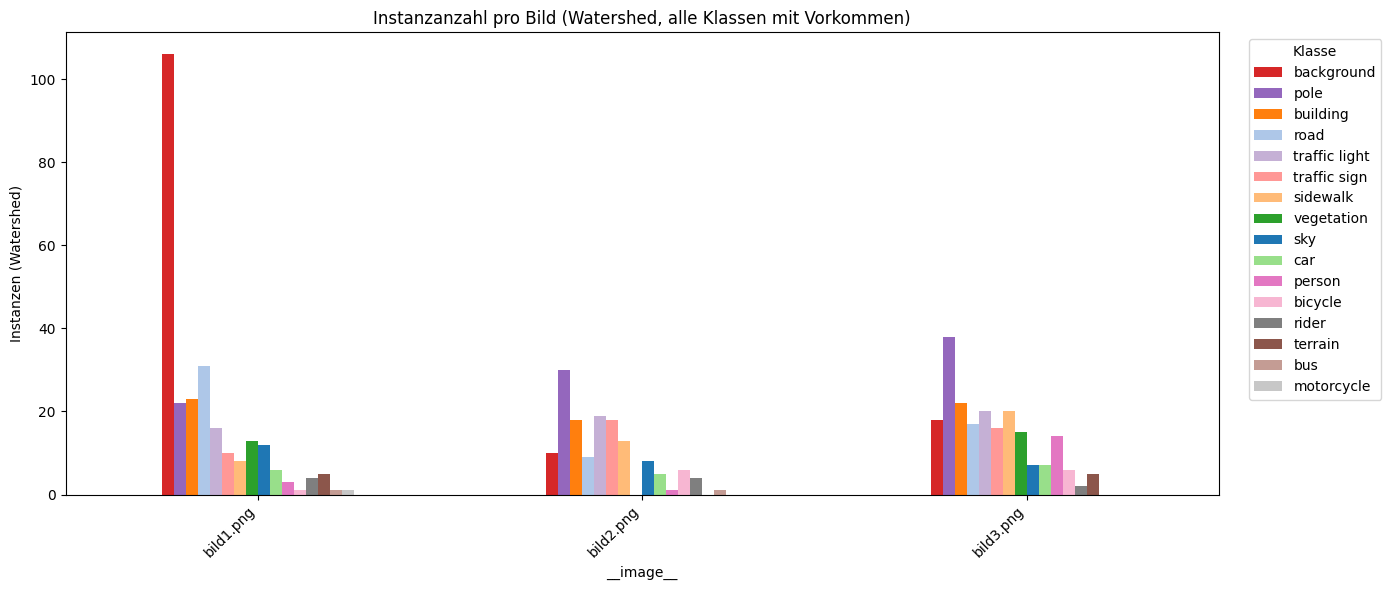

In [123]:
if ws_instances_df.empty:
    print("ws_instances_df ist leer u bitte vorher die Berechnung ausfuhren.")
else:
    ws_total = ws_instances_df.sum().sort_values(ascending=False)
    ws_classes = [c for c in ws_total.index if ws_total[c] > 0]

    # Gesamtinstanzen pro Klasse
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = [palette.get(c, "mediumseagreen") for c in ws_classes]
    ws_total[ws_classes].plot(kind="bar", color=colors, ax=ax)
    ax.set_ylabel("Instanzen (Watershed)")
    ax.set_title("Gesamtanzahl Instanzen pro Klasse (Watershed)")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # Instanzen pro Bild fur alle Klassen mit Vorkommen
    fig, ax = plt.subplots(figsize=(14, 6))
    ws_instances_df[ws_classes].plot(kind="bar", ax=ax, color=[palette.get(c, "mediumseagreen") for c in ws_classes])
    ax.set_ylabel("Instanzen (Watershed)")
    ax.set_title("Instanzanzahl pro Bild (Watershed, alle Klassen mit Vorkommen)")
    ax.legend(title="Klasse", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## Vergleich: Instanzzählung (Connected Components vs. Watershed)
Wir vergleichen die Instanzsummen pro Klasse und pro Bild zwischen beiden Ansätzen. `delta = watershed - connected` zeigt, ob Watershed tendenziell mehr oder weniger Instanzen zählt.

In [124]:
if ws_instances_df.empty:
    print("ws_instances_df ist leer u bitte vorher die Watershed-Berechnung ausfuhren.")
else:
    # Klassenweise Summen und Delta
    connected_total = instances_df.sum()
    ws_total = ws_instances_df.sum()
    compare_df = pd.DataFrame({
        "connected_total": connected_total,
        "watershed_total": ws_total,
        "delta": ws_total - connected_total,
    })
    compare_df = compare_df[(compare_df["connected_total"] != 0) | (compare_df["watershed_total"] != 0)]
    display(compare_df.sort_values("delta", ascending=False))

    # Plot Delta pro Klasse (nur != 0)
    delta_series = compare_df["delta"]
    delta_series = delta_series[delta_series != 0].sort_values()
    if not delta_series.empty:
        ax = delta_series.plot(kind="barh", figsize=(10, 8), color=["salmon" if v > 0 else "steelblue" for v in delta_series])
        ax.set_title("Delta Instanzen pro Klasse (Watershed - Connected)")
        ax.set_xlabel("Delta")
        plt.tight_layout()
        plt.show()
    else:
        print("Keine Abweichungen zwischen den Ansutzen (delta=0 fur alle Klassen).")

    # Bildweise absolute Differenz (Summe uber Klassen)
    aligned_ws = ws_instances_df.reindex(index=instances_df.index).fillna(0)
    delta_per_image = (aligned_ws - instances_df)
    abs_delta_per_image = delta_per_image.abs().sum(axis=1).sort_values(ascending=False)
    print("Top 5 Bilder nach absoluter Differenz (Summe uber Klassen):")
    display(abs_delta_per_image.head(5))


,connected_total,watershed_total,delta
background,134,134,0
bicycle,13,13,0
building,63,63,0
bus,2,2,0
car,18,18,0
motorcycle,1,1,0
person,18,18,0
pole,90,90,0
rider,10,10,0
road,57,57,0


Keine Abweichungen zwischen den Ansutzen (delta=0 fur alle Klassen).
Top 5 Bilder nach absoluter Differenz (Summe uber Klassen):


bild1.png    0
bild2.png    0
bild3.png    0
dtype: int64

## Gestapelte Instanzzahlen pro Bild (CC vs. Watershed)
Gestapelte Balken zeigen die Instanzsummen je Bild ueber alle Klassen.
- CC: Connected Components (Baseline)
- WS: Watershed-Variante (fuer Objektklassen)
Farben folgen der gleichen Klassen-Palette wie oben.

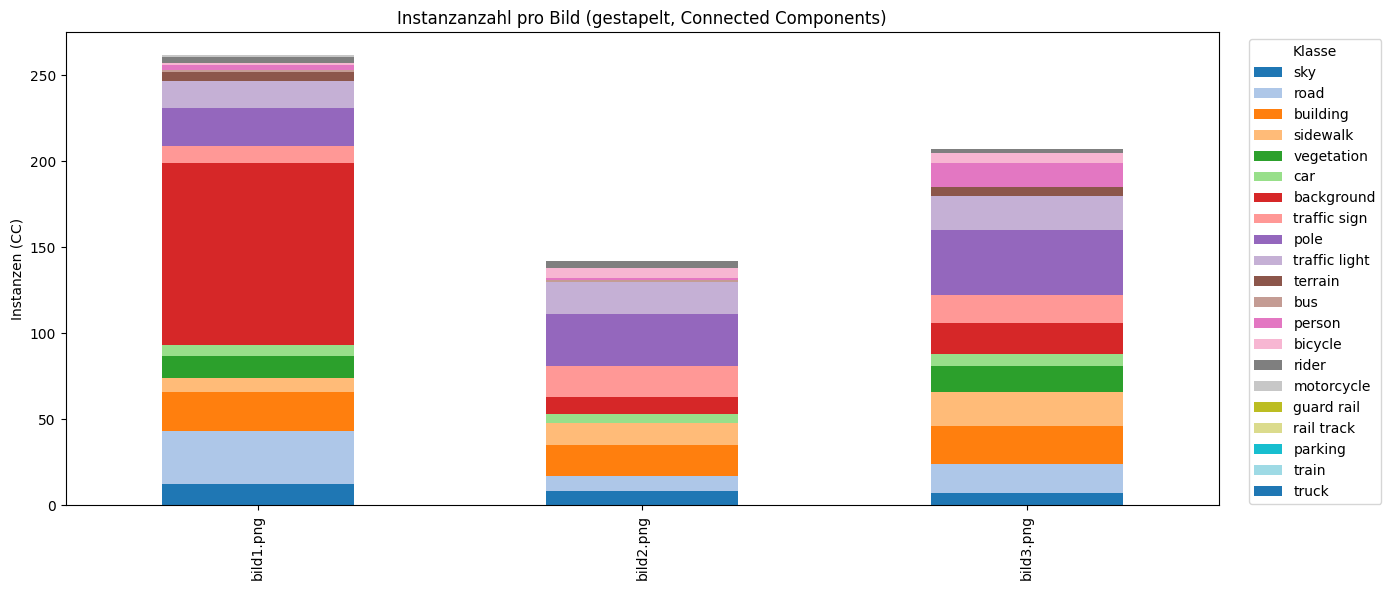

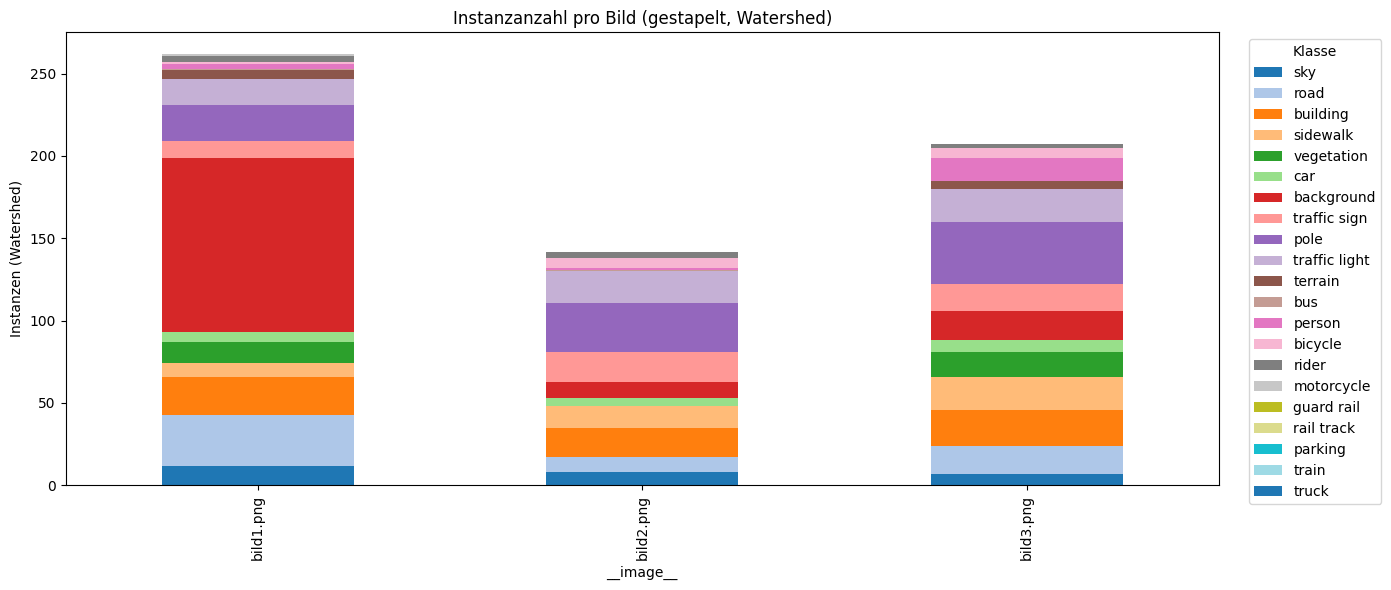

In [125]:
# Klassenreihenfolge: nehme Palette-Reihenfolge, sonst sortiert
if 'palette' in globals() and 'classes_for_plots' in globals():
    classes_order = classes_for_plots
else:
    classes_order = sorted(set(instances_df.columns) | set(ws_instances_df.columns))
    cmap = plt.get_cmap('tab20')
    palette = {cls: cmap(i % cmap.N) for i, cls in enumerate(classes_order)}

cc_aligned = instances_df.reindex(columns=classes_order).fillna(0)
ws_aligned = ws_instances_df.reindex(columns=classes_order).fillna(0)

colors = [palette.get(c, 'gray') for c in classes_order]

fig, ax = plt.subplots(figsize=(14, 6))
cc_aligned.plot(kind='bar', stacked=True, ax=ax, color=colors)
ax.set_ylabel('Instanzen (CC)')
ax.set_title('Instanzanzahl pro Bild (gestapelt, Connected Components)')
ax.legend(title='Klasse', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

if not ws_instances_df.empty:
    fig, ax = plt.subplots(figsize=(14, 6))
    ws_aligned.plot(kind='bar', stacked=True, ax=ax, color=colors)
    ax.set_ylabel('Instanzen (Watershed)')
    ax.set_title('Instanzanzahl pro Bild (gestapelt, Watershed)')
    ax.legend(title='Klasse', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print('ws_instances_df ist leer u Watershed zuerst ausfuhren.')
